# 02. Primera CNN con el dataset de superficies ampliado

### Objetivo
Entrenar **la misma CNN** del cuaderno `2_primera_red` (misma arquitectura, mismo entrenamiento, mismas imágenes) pero ahora con el dataset de superficies de la compañera ampliado en el cuaderno anterior, y ver qué métricas salen. La CNN clasifica el género (0 a 5) de una superficie a partir de una imagen 2D de su nube de puntos.

### Qué cambia respecto a la red con EuLearn
| | EuLearn (`2_primera_red`) | Superficies ampliadas (este cuaderno) |
|---|---|---|
| Clases | 11 (género 0 a 10) | 6 (género 0 a 5) |
| Superficies | 6599 | 2100 (300 originales + 1800 nuevas) |
| Unidad que no se puede repartir entre splits | nudo | **familia** |
| Azar | 9.1 % | 16.7 % |
| Red, optimizador, épocas, imágenes | igual | igual |

### Qué se espera
- Las 10 muestras de una familia son la misma superficie muy deformada, igual que las 20 variantes de un nudo en EuLearn. Por eso el split se hace **por familia**: ninguna familia aparece a la vez en train y en validation o test.
- Como en este dataset el género g son g toros, la cantidad de tinta de la imagen también delata el género (baja al subir el género). Por eso se mantiene la línea base de la tinta, para comprobar si la CNN aporta algo más.

### Pasos
1. Cargar las nubes de puntos y armar el manifest.
2. Separar train, validation y test por familia.
3. Convertir cada nube en una imagen 2D en escala de grises.
4. Medir dos líneas base: el azar y un modelo que solo mira la tinta.
5. Entrenar la CNN y evaluarla en validation.
6. Evaluar la mejor época una sola vez en test.

## 0. Librerías y configuración

In [1]:
import json  # para leer los metadatos de cada superficie
import time  # para medir cuánto tarda cada época
import zipfile  # para descomprimir el dataset si hace falta
from pathlib import Path  # rutas que sirven en cualquier sistema operativo

import matplotlib.pyplot as plt  # para los gráficos
import numpy as np  # para los arreglos numéricos
import pandas as pd  # para las tablas
import torch  # librería de redes neuronales
from torch import nn  # trae las capas (convoluciones, lineales, etc.)
from scipy.spatial.transform import Rotation  # genera rotaciones 3D al azar de forma uniforme
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score  # métricas para evaluar
from sklearn.linear_model import LogisticRegression  # regresión logística para la línea base de la tinta

In [2]:
DATA_DIR = Path("topology_dataset_ampliado/topology_dataset")  # carpeta del dataset ampliado
ZIP_PATH = Path("topology_dataset_ampliado.zip")  # zip del dataset ampliado, por si falta la carpeta
IMAGE_SIZE = 64  # lado de la imagen en píxeles
SPLIT_SEED = 2026  # semilla del split, igual para todas las corridas
SEED = 11  # semilla del entrenamiento
N_CLASSES = 6  # número de géneros, del 0 al 5
ORIGINAL_FAMILIES = 5  # las familias 00 a 04 son las originales; el resto son nuevas
N_TRAIN_FAMILIES = 25  # familias de cada género que van a train
N_VAL_FAMILIES = 5  # familias de cada género que van a validation (las demás van a test)
VAL_VIEWS = 1  # vistas fijas por superficie en validation
TEST_VIEWS = 3  # vistas fijas por superficie en test
BATCH_SIZE = 64  # tamaño del batch
EPOCHS = 15  # número de épocas
LEARNING_RATE = 1e-3  # tasa de aprendizaje de AdamW

np.random.seed(SEED)  # fija la semilla de numpy
torch.manual_seed(SEED)  # fija la semilla de torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # usa la gpu si hay, si no la cpu
print(device)  # muestra qué dispositivo se usa

if not DATA_DIR.exists():  # si la carpeta no está descomprimida
    with zipfile.ZipFile(ZIP_PATH) as zf:  # abre el zip del dataset ampliado
        zf.extractall("topology_dataset_ampliado")  # lo descomprime

cpu


## 1. Cargar los datos

Cada superficie es un archivo `.npy` con 3000 puntos 3D en `genus_X/pointclouds`, y un `.json` con sus metadatos en `genus_X/metadata`. Se arma un **manifest** (una fila por superficie) leyendo los metadatos, y todas las nubes se cargan en memoria, porque son pequeñas (2100 x 3000 x 3).

La columna `group` identifica la familia (por ejemplo `g3_family07`). Es la unidad que se reparte entre splits, equivalente al nudo en EuLearn.

In [3]:
records = []  # una fila por superficie
for genus_dir in sorted(DATA_DIR.glob("genus_*")):  # recorre las carpetas de género
    for meta_path in sorted((genus_dir / "metadata").glob("*.json")):  # recorre sus metadatos
        meta = json.loads(meta_path.read_text())  # lee el metadata
        records.append(dict(  # agrega una fila al manifest
            sample_id=meta_path.stem,  # nombre de la superficie, por ejemplo g3_family07_sample002
            genus=meta["genus"],  # género (la etiqueta)
            family=meta["family"],  # número de familia
            group=f"g{meta['genus']}_family{meta['family']:02d}",  # identificador de la familia
            sample=meta["sample"],  # número de muestra dentro de la familia
            surface_type=meta["surface_type"],  # tipo de superficie
            origin="original" if meta["family"] < ORIGINAL_FAMILIES else "nueva",  # de dónde viene
            n_points=meta["n_points"],  # puntos de la nube
            file=genus_dir / "pointclouds" / f"{meta_path.stem}.npy",  # ruta de la nube
        ))  # agrega la fila
manifest = pd.DataFrame(records)  # tabla con todas las superficies
points_by_id = {row.sample_id: np.load(row.file).astype(np.float32) for row in manifest.itertuples()}  # carga todas las nubes en memoria


def load_points(row):  # devuelve los puntos (n, 3) de una fila del manifest
    return points_by_id[row.sample_id]  # busca la nube por su nombre


print(len(manifest), "superficies")  # cuántas filas hay
manifest.drop(columns="file").head()  # primeras filas para ver las columnas

2100 superficies


,sample_id,genus,family,group,sample,surface_type,origin,n_points
0,g0_family00_sample000,0,0,g0_family00,0,sphere_like,original,3000
1,g0_family00_sample001,0,0,g0_family00,1,sphere_like,original,3000
2,g0_family00_sample002,0,0,g0_family00,2,sphere_like,original,3000
3,g0_family00_sample003,0,0,g0_family00,3,sphere_like,original,3000
4,g0_family00_sample004,0,0,g0_family00,4,sphere_like,original,3000


In [4]:
pd.crosstab(manifest["genus"], manifest["origin"], margins=True)  # superficies por género y origen

origin,nueva,original,All
genus,,,
0,300,50,350
1,300,50,350
2,300,50,350
3,300,50,350
4,300,50,350
5,300,50,350
All,1800,300,2100


## 2. Split por familia

Las 10 muestras de una familia son la misma superficie base deformada de 10 maneras. Si se repartieran filas al azar, validation y test quedarían llenos de variantes de lo que ya se vio en train y la accuracy saldría inflada. Por eso se reparten **familias**: en cada género hay 35 familias (5 originales y 30 nuevas); 25 van a train, 5 a validation y 5 a test, elegidas al azar con una semilla fija.

In [5]:
rng = np.random.default_rng(SPLIT_SEED)  # generador de números aleatorios con la semilla del split
group_split = {}  # aquí se guarda a qué split va cada familia
for genus in range(N_CLASSES):  # recorre los géneros
    groups = sorted(manifest.loc[manifest["genus"] == genus, "group"].unique())  # familias de este género, ordenadas
    groups = list(rng.permutation(groups))  # las baraja con la semilla
    for group in groups[:N_TRAIN_FAMILIES]:  # las primeras van a train
        group_split[group] = "train"  # asigna train
    for group in groups[N_TRAIN_FAMILIES:N_TRAIN_FAMILIES + N_VAL_FAMILIES]:  # las siguientes van a validation
        group_split[group] = "val"  # asigna validation
    for group in groups[N_TRAIN_FAMILIES + N_VAL_FAMILIES:]:  # las demás van a test
        group_split[group] = "test"  # asigna test

manifest["split"] = manifest["group"].map(group_split)  # agrega la columna split al manifest
assert manifest.groupby("group")["split"].nunique().max() == 1  # comprueba que ninguna familia quedó en dos splits
manifest.groupby(["genus", "split"])["group"].nunique().unstack()  # familias por género y split

split,test,train,val
genus,,,
0,5,25,5
1,5,25,5
2,5,25,5
3,5,25,5
4,5,25,5
5,5,25,5


In [6]:
print(manifest["split"].value_counts().to_string())  # superficies por split
pd.crosstab(manifest["split"], manifest["origin"])  # cuántas originales y nuevas hay en cada split

split
train    1500
test      300
val       300


origin,nueva,original
split,,
test,250,50
train,1300,200
val,250,50


## 3. De nube de puntos a imagen

Igual que en la red con EuLearn, la CNN recibe imágenes, así que cada superficie se proyecta a 2D:

1. Se centra la nube y se escala para que quepa en una esfera de radio 1. Así todas las superficies tienen el mismo tamaño en la imagen y la red no puede usar el tamaño como pista (en este dataset las cadenas de toros de género alto son mucho más largas).
2. Se rota con una rotación 3D al azar. El género no cambia al rotar, así que cada rotación es una imagen nueva válida de la misma superficie.
3. Se proyecta sobre el plano x, y y cada punto pinta su píxel. El tono depende de la profundidad z: lo que está cerca se ve más oscuro.

In [7]:
def render(points, rotation, size=IMAGE_SIZE):  # convierte una nube 3d en una imagen 2d
    centered = points - points.mean(axis=0)  # centra la nube en el origen
    scaled = centered / np.linalg.norm(centered, axis=1).max()  # escala para que el punto más lejano quede a distancia 1
    rotated = scaled @ rotation.T  # aplica la rotación
    pixels = ((rotated[:, :2] + 1) / 2 * (size - 1)).round().astype(int)  # pasa x, y de [-1, 1] a índices de píxel
    depth = (rotated[:, 2] + 1) / 2  # profundidad de 0 (lejos) a 1 (cerca)
    image = np.zeros((size, size), dtype=np.float32)  # imagen vacía
    np.maximum.at(image, (size - 1 - pixels[:, 1], pixels[:, 0]), 0.25 + 0.75 * depth)  # cada píxel se queda con el punto más cercano; la fila se invierte para que y crezca hacia arriba
    return image  # devuelve la imagen


def random_rotation(rng):  # rotación 3d uniforme al azar
    return Rotation.random(random_state=rng).as_matrix()  # como matriz 3x3

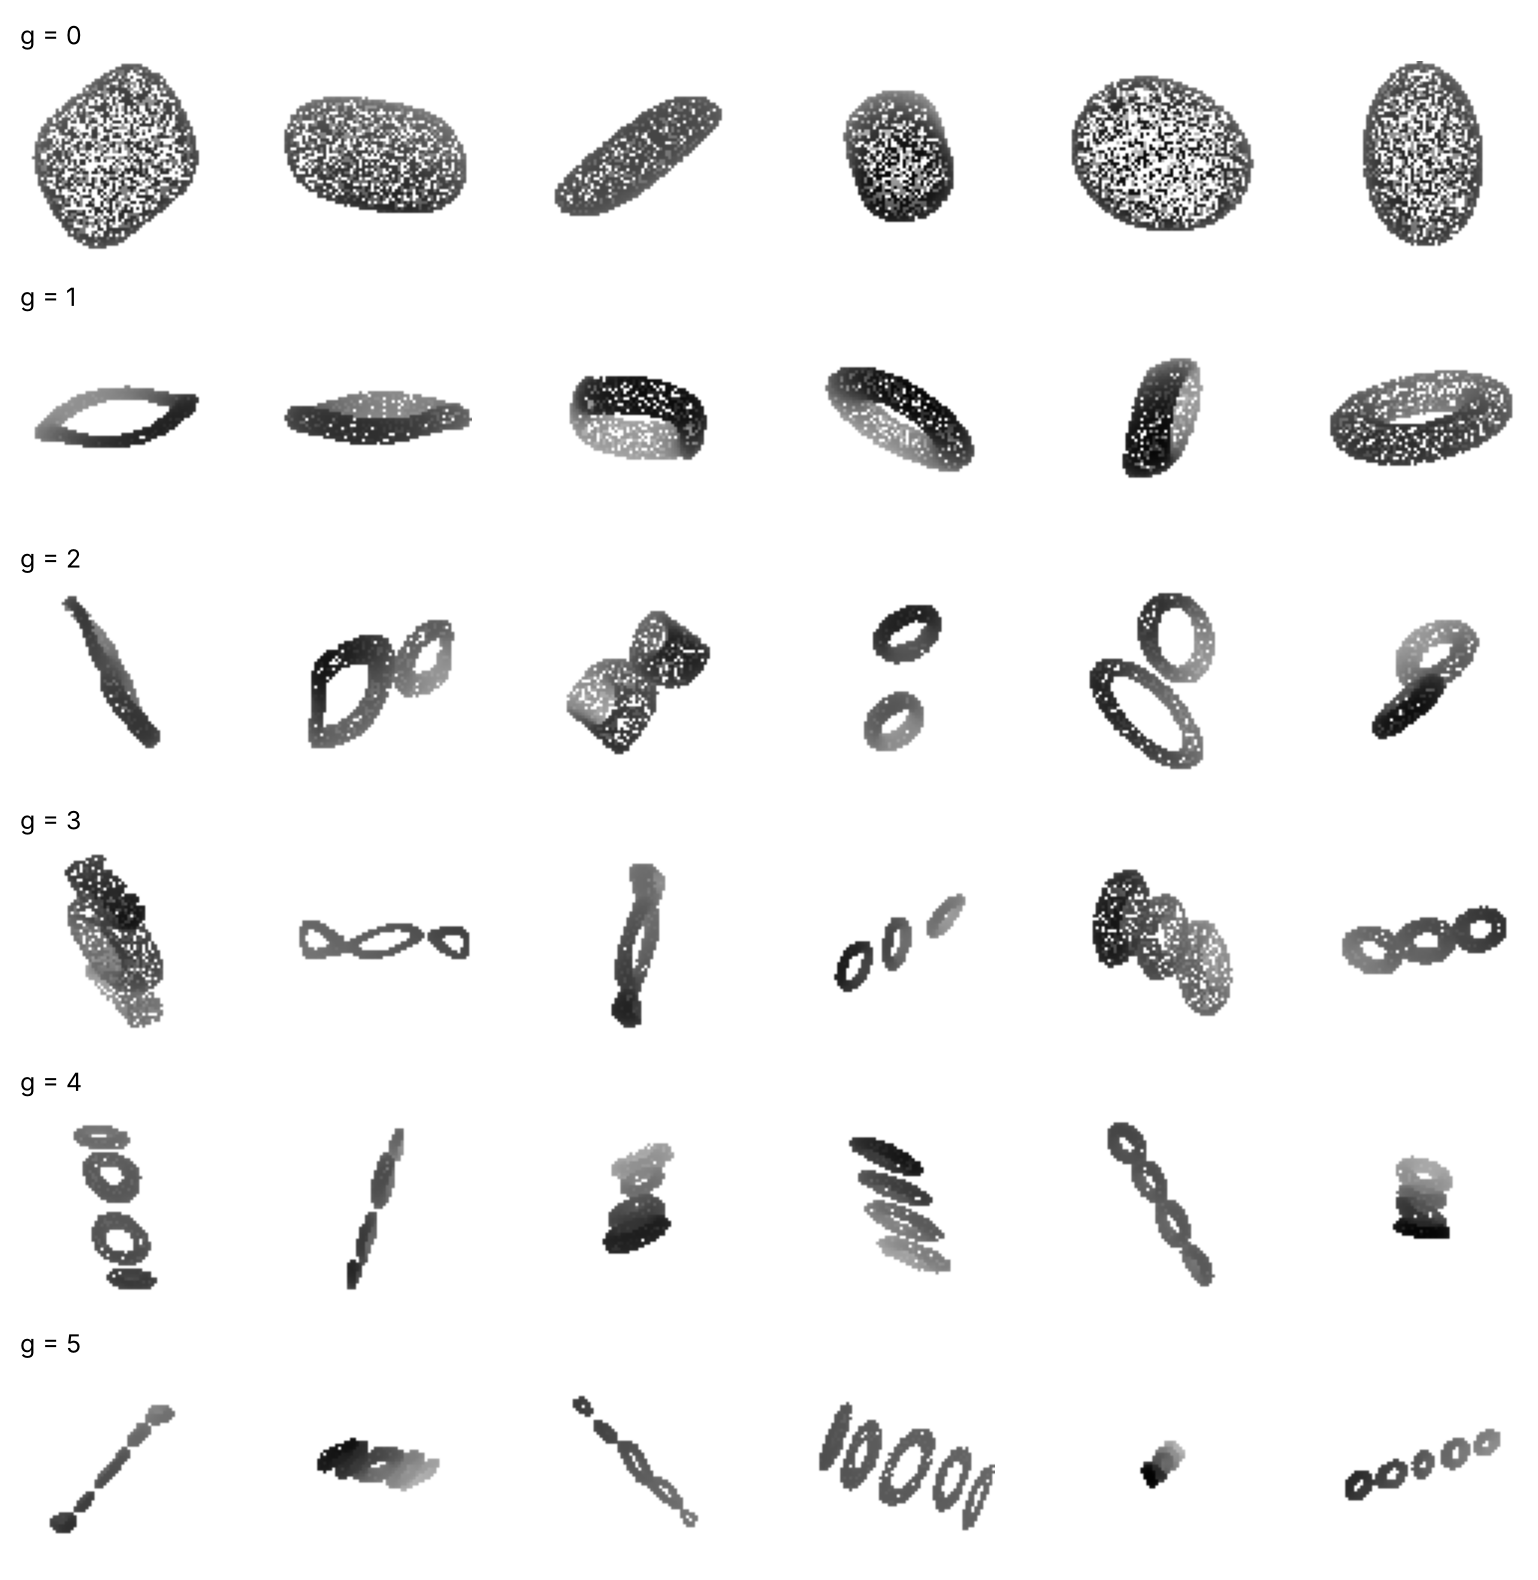

In [8]:
fig_rng = np.random.default_rng(0)  # generador para las figuras
fig, axes = plt.subplots(N_CLASSES, 6, figsize=(8, 8))  # una fila por género y 6 columnas
for genus in range(N_CLASSES):  # recorre los géneros
    subset = manifest[(manifest["genus"] == genus) & (manifest["split"] == "train") & (manifest["sample"] == 0)]  # la muestra 0 de cada familia de train
    examples = subset.head(6)  # las primeras 6 familias
    for ax, row in zip(axes[genus], examples.itertuples()):  # recorre las columnas
        ax.imshow(render(load_points(row), random_rotation(fig_rng)), cmap="gray_r", vmin=0, vmax=1)  # dibuja con una rotación al azar
    for ax in axes[genus]:  # recorre las columnas de la fila
        ax.axis("off")  # quita los ejes
    axes[genus, 0].set_title(f"g = {genus}", fontsize=9, loc="left")  # escribe el género en la primera columna
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

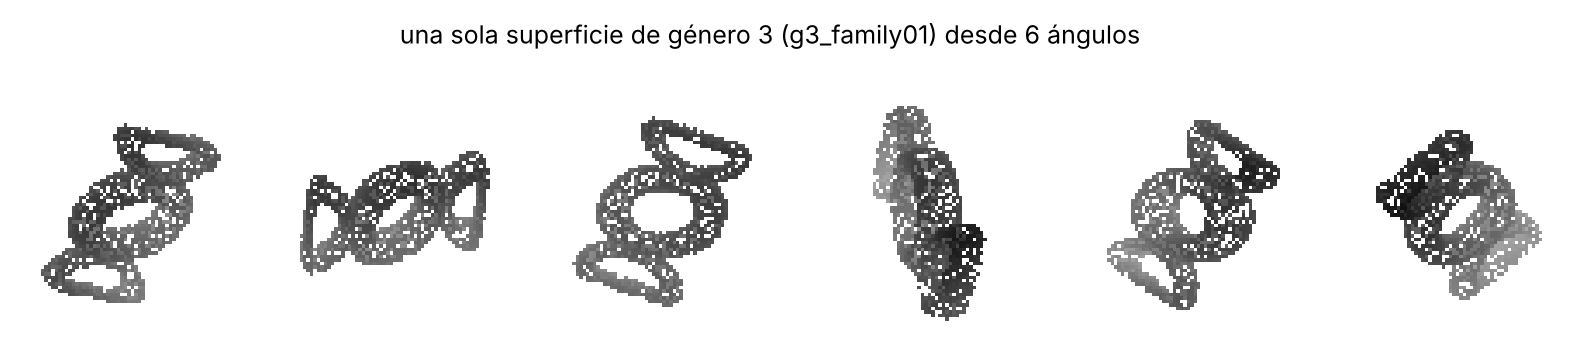

In [9]:
row = manifest[(manifest["genus"] == 3) & (manifest["split"] == "train")].iloc[0]  # una superficie de género 3
fig, axes = plt.subplots(1, 6, figsize=(10, 2))  # 6 paneles en una fila
for ax in axes:  # recorre los paneles
    ax.imshow(render(load_points(row), random_rotation(fig_rng)), cmap="gray_r", vmin=0, vmax=1)  # dibuja una rotación distinta
    ax.axis("off")  # quita los ejes
fig.suptitle(f"una sola superficie de género 3 ({row.group}) desde 6 ángulos", fontsize=9)  # título con la familia
plt.show()  # muestra la figura

## 4. PyTorch

- **Train:** cada vez que se pide una imagen se genera una rotación nueva. Es la augmentation: en cada época la red ve cada superficie desde un ángulo distinto.
- **Validation y test:** las vistas se generan una sola vez con una semilla fija, para que todas las épocas (y todas las corridas) se evalúen sobre las mismas imágenes. En validation hay 1 vista por superficie y en test 3.

In [10]:
class TrainDataset(torch.utils.data.Dataset):  # dataset que genera una rotación nueva cada vez

    def __init__(self, frame, seed):  # recibe las filas del split y una semilla
        self.frame = frame.reset_index(drop=True)  # guarda las filas de este split
        self.rng = np.random.default_rng(seed)  # generador propio para las rotaciones

    def __len__(self):  # tamaño del dataset
        return len(self.frame)  # número de superficies

    def __getitem__(self, index):  # devuelve una imagen y su etiqueta
        row = self.frame.iloc[index]  # fila pedida
        image = render(load_points(row), random_rotation(self.rng))  # imagen con una rotación al azar
        return torch.from_numpy(image)[None], int(row.genus)  # tensor con un canal: forma (1, 64, 64)


def fixed_views(frame, views, seed):  # genera las imágenes fijas de un split
    rng = np.random.default_rng(seed)  # generador con semilla fija
    images, labels = [], []  # listas de imágenes y etiquetas
    for row in frame.itertuples():  # recorre las superficies
        for _ in range(views):  # una o varias vistas por superficie
            images.append(render(load_points(row), random_rotation(rng)))  # imagen con una rotación al azar
            labels.append(row.genus)  # su etiqueta
    return torch.from_numpy(np.stack(images))[:, None], torch.tensor(labels)  # tensor (n, 1, 64, 64) y vector de etiquetas


train_frame = manifest[manifest["split"] == "train"]  # filas de train
val_frame = manifest[manifest["split"] == "val"]  # filas de validation
test_frame = manifest[manifest["split"] == "test"]  # filas de test
train_dataset = TrainDataset(train_frame, seed=SEED)  # dataset de train
val_images, val_labels = fixed_views(val_frame, VAL_VIEWS, seed=SPLIT_SEED)  # imágenes fijas de validation
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)  # loader que baraja train en cada época
val_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(val_images, val_labels), batch_size=256)  # loader de validation sin barajar
print(len(train_dataset), "en train,", len(val_labels), "en validation")  # tamaños

1500 en train, 300 en validation


## 5. Líneas base

Antes de entrenar hay que saber contra qué se compara la red.

- **Azar:** con 6 clases balanceadas, adivinar da más o menos 1/6 = 16.7 %.
- **Tinta:** una regresión logística que solo ve la proporción de píxeles pintados. Como el género g son g toros, y la nube se reescala para caber en la esfera unitaria, cuantos más toros hay más fina y larga queda la cadena y **menos píxeles pinta** (la tinta baja al subir el género), así que este modelo tan simple debería acertar algo. Si la CNN no lo supera con claridad, solo estaría usando la misma pista.

In [11]:
def ink(images):  # proporción de píxeles pintados de cada imagen
    return (images > 0).float().mean(dim=(1, 2, 3)).numpy()  # fracción de píxeles distintos de cero


train_images_fixed, train_labels_fixed = fixed_views(train_frame, 1, seed=SEED)  # imágenes fijas de train solo para esta línea base
ink_train = ink(train_images_fixed)  # tinta de train
ink_val = ink(val_images)  # tinta de validation

ink_table = pd.DataFrame({"genus": train_labels_fixed.numpy(), "tinta": ink_train})  # la tinta por género en train
print(ink_table.groupby("genus")["tinta"].median().round(3).to_string())  # mediana por género

ink_model = LogisticRegression(max_iter=1000).fit(ink_train[:, None], train_labels_fixed.numpy())  # regresión logística con la tinta como único rasgo
ink_pred = ink_model.predict(ink_val[:, None])  # predicciones en validation
baselines = pd.DataFrame(  # tabla de las líneas base
    {  # columnas de la tabla
        "accuracy": [1 / N_CLASSES, accuracy_score(val_labels, ink_pred)],  # accuracy del azar y de la tinta
        "macro_f1": [np.nan, f1_score(val_labels, ink_pred, average="macro")],  # macro f1 (el azar no tiene)
    },  # fin de las columnas
    index=["azar", "tinta"],  # nombre de cada línea base
).round(3)  # resultados de las líneas base
baselines  # muestra la tabla

genus
0    0.340
1    0.246
2    0.170
3    0.124
4    0.102
5    0.085


,accuracy,macro_f1
azar,0.167,NaN
tinta,0.393,0.344


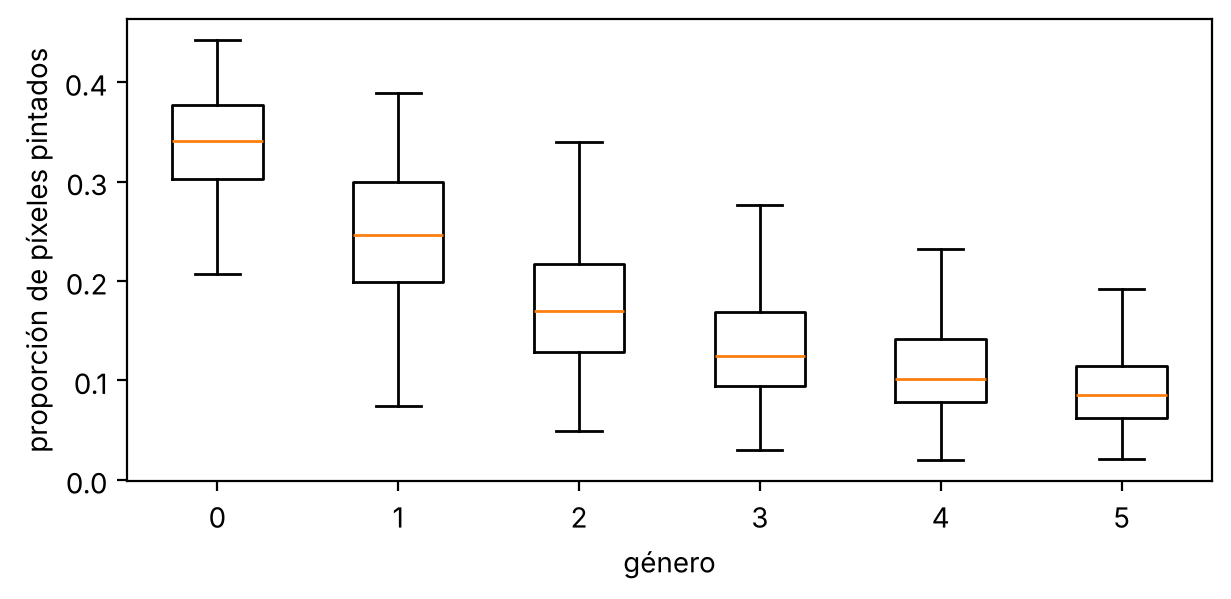

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))  # boxplot de la tinta por género
ax.boxplot([ink_table.loc[ink_table["genus"] == g, "tinta"] for g in range(N_CLASSES)], showfliers=False)  # una caja por género
ax.set_xticklabels(range(N_CLASSES))  # etiquetas del eje x de 0 a 5
ax.set_xlabel("género")  # nombre del eje x
ax.set_ylabel("proporción de píxeles pintados")  # nombre del eje y
plt.show()  # muestra la figura

## 6. La red

Es **exactamente la misma CNN** de `2_primera_red`; solo cambia el número de neuronas de salida (6 en lugar de 11):

- 4 bloques. Cada uno tiene una convolución 3x3, BatchNorm, ReLU y max pooling 2x2. El tamaño pasa de 64 a 32, 16, 8 y 4 píxeles, y los canales de 1 a 32, 64, 128 y 128.
- Average pooling global, que resume cada canal en un número.
- Una capa oculta de 128 neuronas con dropout y la salida de 6 neuronas, una por género.

In [13]:
class GenusCNN(nn.Module):  # cnn para clasificar el género

    def __init__(self, n_classes=N_CLASSES):  # recibe el número de clases
        super().__init__()  # inicializa nn.Module
        channels = [1, 32, 64, 128, 128]  # canales de entrada y salida de cada bloque
        layers = []  # lista de capas de la parte convolucional
        for c_in, c_out in zip(channels[:-1], channels[1:]):  # un bloque por cada par de canales
            layers += [  # el bloque completo
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),  # convolución 3x3; padding 1 conserva el tamaño
                nn.BatchNorm2d(c_out),  # normaliza las activaciones del batch
                nn.ReLU(),  # no linealidad
                nn.MaxPool2d(2),  # reduce el tamaño a la mitad
            ]  # el bloque completo
        self.features = nn.Sequential(*layers)  # junta los bloques
        self.pool = nn.AdaptiveAvgPool2d(1)  # promedio global: un número por canal
        self.head = nn.Sequential(  # cabeza clasificadora
            nn.Flatten(),  # aplana (batch, 128, 1, 1) a (batch, 128)
            nn.Linear(channels[-1], 128),  # capa oculta
            nn.ReLU(),  # no linealidad
            nn.Dropout(0.3),  # apaga al azar el 30 % de las neuronas en entrenamiento
            nn.Linear(128, n_classes),  # una salida por género
        )  # fin de la cabeza

    def forward(self, x):  # paso hacia adelante
        return self.head(self.pool(self.features(x)))  # convoluciones, pooling y cabeza


model = GenusCNN().to(device)  # crea la red
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)  # cuenta los parámetros entrenables
print(f"{n_params:,} parámetros")  # muestra el número

258,246 parámetros


## 7. Entrenamiento

- **Pérdida:** entropía cruzada.
- **Optimizador:** AdamW con tasa de aprendizaje 0.001.
- **Checkpoint:** en cada época se mide la pérdida de validation y se guarda la red de la mejor época. Test no se toca durante el entrenamiento.

In [14]:
def evaluate(model, loader):  # evalúa la red sobre un loader
    model.eval()  # modo evaluación: apaga dropout y usa las estadísticas fijas de BatchNorm
    losses, preds, labels = [], [], []  # acumuladores
    with torch.no_grad():  # sin gradientes para ir más rápido
        for x, y in loader:  # recorre los batches
            x, y = x.to(device), y.to(device)  # pasa al dispositivo
            logits = model(x)  # salidas de la red
            losses.append(nn.functional.cross_entropy(logits, y).item() * len(y))  # pérdida de este batch multiplicada por su tamaño
            preds.append(logits.argmax(1).cpu())  # clase con mayor puntaje
            labels.append(y.cpu())  # etiquetas reales
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()  # junta todo
    return sum(losses) / len(labels), accuracy_score(labels, preds), f1_score(labels, preds, average="macro"), preds, labels  # pérdida promedio, accuracy, macro f1, predicciones y etiquetas


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)  # optimizador
loss_fn = nn.CrossEntropyLoss()  # función de pérdida
history = []  # historial por época
best_val_loss = float("inf")  # mejor pérdida de validation hasta ahora
for epoch in range(1, EPOCHS + 1):  # recorre las épocas
    start = time.time()  # hora de inicio
    model.train()  # modo entrenamiento
    train_loss, train_correct, seen = 0.0, 0, 0  # acumuladores de train
    for x, y in train_loader:  # recorre los batches
        x, y = x.to(device), y.to(device)  # pasa al dispositivo
        optimizer.zero_grad()  # borra los gradientes anteriores
        logits = model(x)  # salidas
        loss = loss_fn(logits, y)  # pérdida
        loss.backward()  # calcula los gradientes
        optimizer.step()  # actualiza los pesos
        train_loss += loss.item() * len(y)  # suma la pérdida del batch
        train_correct += (logits.argmax(1) == y).sum().item()  # suma los aciertos
        seen += len(y)  # suma las imágenes vistas
    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader)  # evalúa en validation
    is_best = val_loss < best_val_loss  # ¿es la mejor época?
    if is_best:  # si lo es
        best_val_loss = val_loss  # actualiza la mejor pérdida
        torch.save(model.state_dict(), "mejor_modelo_ampliado.pt")  # guarda los pesos
    history.append(dict(epoch=epoch, train_loss=train_loss / seen, train_acc=train_correct / seen, val_loss=val_loss, val_acc=val_acc, val_macro_f1=val_f1, best=int(is_best)))  # guarda la fila del historial
    print(f"época {epoch:2d}  train_acc {train_correct / seen:.3f}  val_acc {val_acc:.3f}  "  # arma el mensaje de progreso
          f"val_f1 {val_f1:.3f}  val_loss {val_loss:.3f}  {'*' if is_best else ' '}  {time.time() - start:.0f} s")  # imprime el progreso

history = pd.DataFrame(history)  # historial como tabla

época  1  train_acc 0.391  val_acc 0.227  val_f1 0.145  val_loss 1.699  *  7 s


época  2  train_acc 0.507  val_acc 0.467  val_f1 0.415  val_loss 1.161  *  6 s


época  3  train_acc 0.512  val_acc 0.310  val_f1 0.264  val_loss 1.508     6 s


época  4  train_acc 0.525  val_acc 0.457  val_f1 0.439  val_loss 1.102  *  6 s


época  5  train_acc 0.574  val_acc 0.380  val_f1 0.334  val_loss 1.280     6 s


época  6  train_acc 0.569  val_acc 0.473  val_f1 0.447  val_loss 1.468     6 s


... (5 outputs left out)

época 12  train_acc 0.654  val_acc 0.533  val_f1 0.499  val_loss 1.050     5 s


época 13  train_acc 0.648  val_acc 0.483  val_f1 0.459  val_loss 1.134     6 s


época 14  train_acc 0.664  val_acc 0.533  val_f1 0.513  val_loss 1.127     5 s


época 15  train_acc 0.673  val_acc 0.673  val_f1 0.662  val_loss 0.730  *  5 s


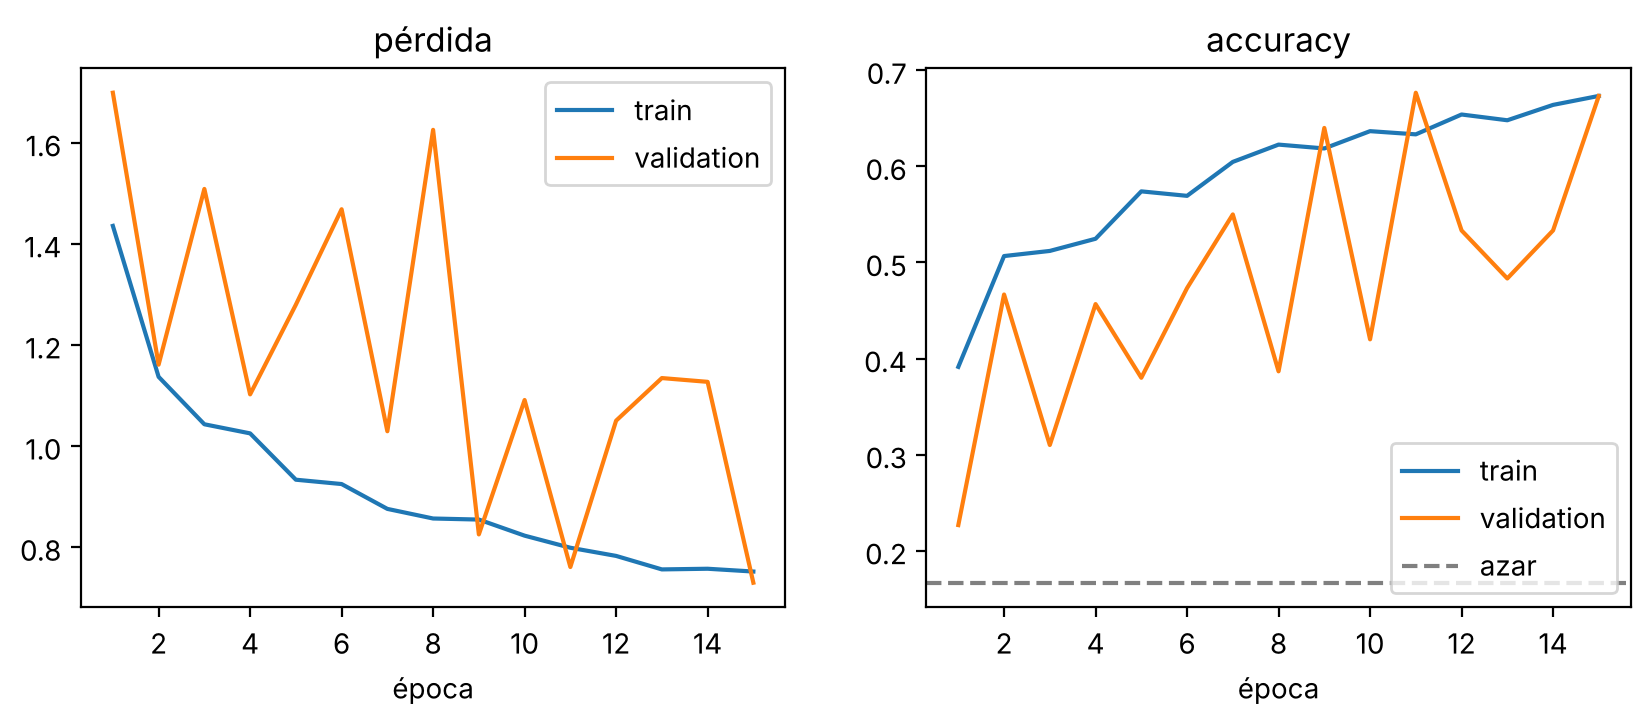

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))  # dos paneles: pérdida y accuracy
axes[0].plot(history["epoch"], history["train_loss"], label="train")  # pérdida de train
axes[0].plot(history["epoch"], history["val_loss"], label="validation")  # pérdida de validation
axes[0].set_title("pérdida")  # título del panel
axes[1].plot(history["epoch"], history["train_acc"], label="train")  # accuracy de train
axes[1].plot(history["epoch"], history["val_acc"], label="validation")  # accuracy de validation
axes[1].axhline(1 / N_CLASSES, color="gray", ls="--", label="azar")  # línea del azar
axes[1].set_title("accuracy")  # título del panel
for ax in axes:  # recorre los paneles
    ax.set_xlabel("época")  # nombre del eje x
    ax.legend()  # leyenda
plt.show()  # muestra la figura

## 8. Evaluación en validation

Se carga la mejor época y se miran tres cosas:

- las métricas globales frente a las líneas base;
- la matriz de confusión;
- qué tan lejos queda el género predicho del real. El género es un número, así que no es lo mismo confundir 4 con 5 que 0 con 5.

In [16]:
model.load_state_dict(torch.load("mejor_modelo_ampliado.pt", weights_only=True))  # carga los pesos de la mejor época
val_loss, val_acc, val_f1, val_pred, val_true = evaluate(model, val_loader)  # evalúa en validation
best = history.loc[history["val_loss"].idxmin()]  # fila de la mejor época
results = pd.concat([  # junta las tablas
    baselines,  # azar y tinta
    pd.DataFrame({"accuracy": [val_acc], "macro_f1": [val_f1]}, index=["cnn"]).round(3),  # la cnn
])  # tabla de resultados junto a las líneas base
print(f"mejor época {int(best.epoch)}, train_acc {best.train_acc:.3f}, gap {best.train_acc - val_acc:.3f}")  # muestra la mejor época y el gap
results  # muestra la tabla

mejor época 15, train_acc 0.673, gap 0.000


,accuracy,macro_f1
azar,0.167,NaN
tinta,0.393,0.344
cnn,0.673,0.662


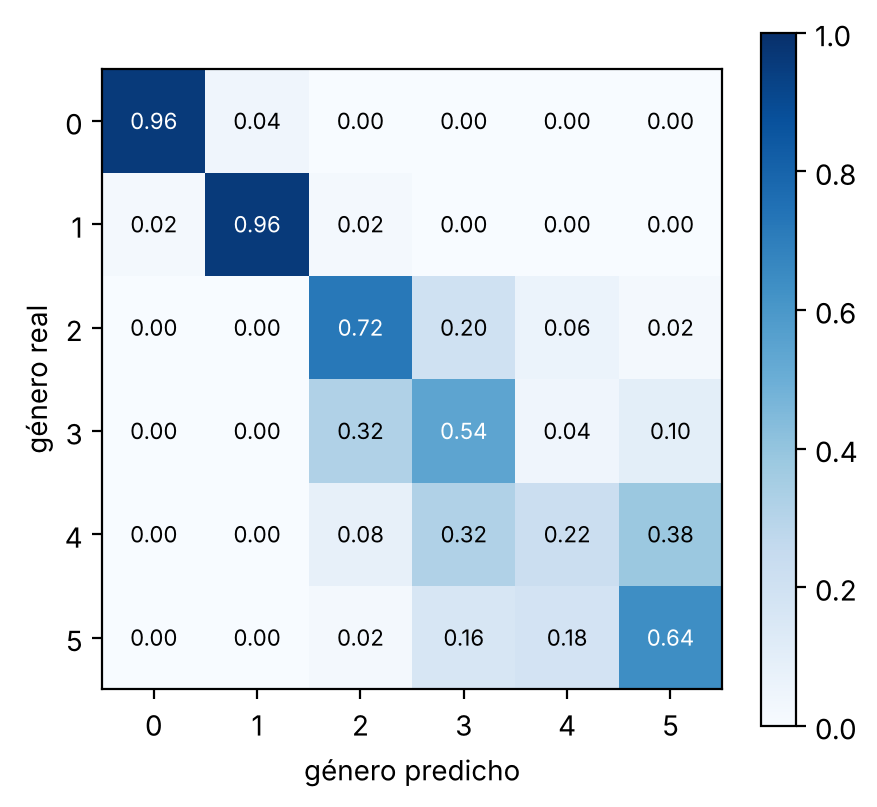

In [17]:
cm = confusion_matrix(val_true, val_pred, labels=range(N_CLASSES))  # matriz de confusión: filas = real, columnas = predicho
cm_norm = cm / cm.sum(axis=1, keepdims=True)  # normalizada por fila: proporción de cada género real
fig, ax = plt.subplots(figsize=(5, 4.5))  # figura
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)  # mapa de calor
ax.set_xticks(range(N_CLASSES))  # marcas del eje x
ax.set_yticks(range(N_CLASSES))  # marcas del eje y
ax.set_xlabel("género predicho")  # nombre del eje x
ax.set_ylabel("género real")  # nombre del eje y
for i in range(N_CLASSES):  # recorre las filas
    for j in range(N_CLASSES):  # recorre las columnas
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm_norm[i, j] > 0.5 else "black")  # escribe cada valor en su casilla
plt.colorbar(im)  # barra de color
plt.show()  # muestra la figura

In [18]:
recall = pd.Series(np.diag(cm) / cm.sum(axis=1), name="recall").round(3)  # recall por género: aciertos / total de ese género
distance = np.abs(val_pred - val_true)  # distancia entre el género predicho y el real
print("distancia media entre predicho y real:", distance.mean().round(2))  # resumen de los errores
print("errores a distancia 1:", (distance == 1).sum(), "de", (distance > 0).sum())  # cuántos errores son por un solo género

shuffle_rng = np.random.default_rng(0)  # generador para el baremo del azar
random_distance = np.mean([np.abs(shuffle_rng.permutation(val_pred) - val_true).mean() for _ in range(200)])  # distancia media si se barajan las predicciones
print("distancia media si las predicciones fueran al azar:", round(random_distance, 2))  # la compara con la de la red
recall.to_frame().T  # muestra el recall por género

distancia media entre predicho y real: 0.41
errores a distancia 1: 76 de 98
distancia media si las predicciones fueran al azar: 1.93


,0,1,2,3,4,5
recall,0.96,0.96,0.72,0.54,0.22,0.64


In [19]:
print("correlación tinta - género real:", np.corrcoef(ink_val, val_true)[0, 1].round(3))  # cuánto se parece la tinta al género real
print("correlación tinta - género predicho:", np.corrcoef(ink_val, val_pred)[0, 1].round(3))  # cuánto se parece la tinta al género que predice la red

correlación tinta - género real: -0.794
correlación tinta - género predicho: -0.82


## 9. Evaluación final en test

Validation sirvió para elegir la mejor época, así que sus métricas son algo optimistas. Test son familias que la red nunca vio ni se usaron para decidir nada. Se evalúa **una sola vez** la mejor época, con 3 vistas fijas por superficie, y se compara con las mismas líneas base.

In [20]:
test_images, test_labels = fixed_views(test_frame, TEST_VIEWS, seed=SPLIT_SEED + 1)  # imágenes fijas de test
test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(test_images, test_labels), batch_size=256)  # loader de test
test_loss, test_acc, test_f1, test_pred, test_true = evaluate(model, test_loader)  # evalúa la mejor época en test
ink_test = ink(test_images)  # tinta de test
ink_test_pred = ink_model.predict(ink_test[:, None])  # predicciones del modelo de tinta en test
test_results = pd.DataFrame(  # tabla de test
    {  # columnas de la tabla
        "accuracy": [1 / N_CLASSES, accuracy_score(test_labels, ink_test_pred), test_acc],  # accuracy del azar, la tinta y la cnn
        "macro_f1": [np.nan, f1_score(test_labels, ink_test_pred, average="macro"), test_f1],  # macro f1
    },  # fin de las columnas
    index=["azar", "tinta", "cnn"],  # nombre de cada fila
).round(3)  # tabla de test
print(len(test_labels), "imágenes de test")  # cuántas imágenes se evaluaron
test_results  # muestra la tabla

900 imágenes de test


,accuracy,macro_f1
azar,0.167,NaN
tinta,0.396,0.329
cnn,0.711,0.692


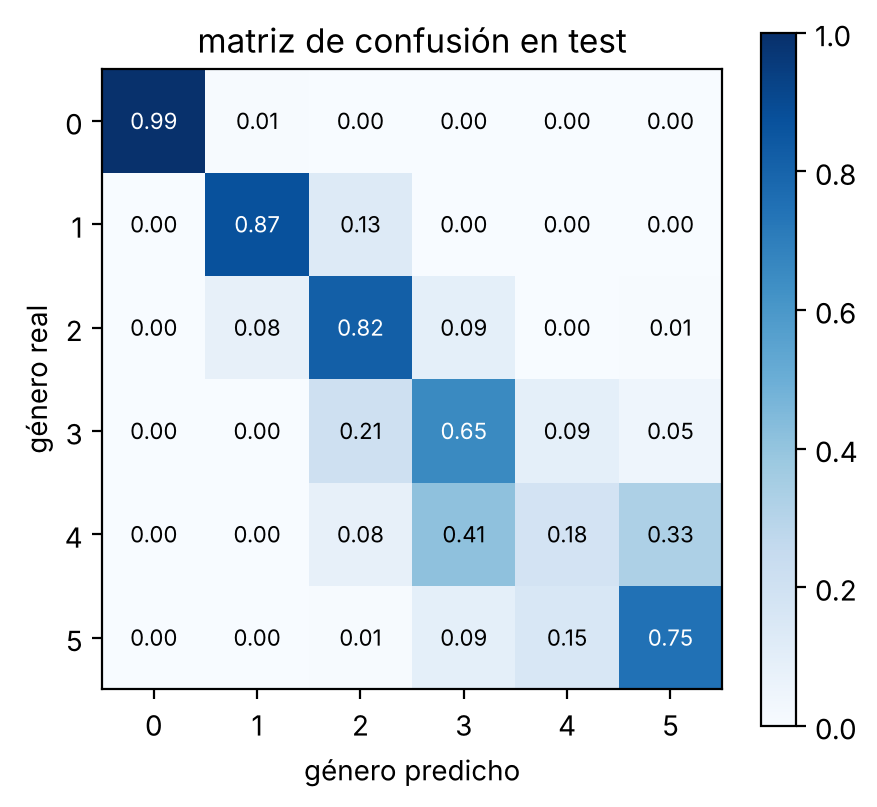

recall por género en test: [0.993 0.873 0.82  0.653 0.18  0.747]


In [21]:
cm_test = confusion_matrix(test_true, test_pred, labels=range(N_CLASSES))  # matriz de confusión en test
cm_test_norm = cm_test / cm_test.sum(axis=1, keepdims=True)  # normalizada por fila
fig, ax = plt.subplots(figsize=(5, 4.5))  # figura
im = ax.imshow(cm_test_norm, cmap="Blues", vmin=0, vmax=1)  # mapa de calor
ax.set_xticks(range(N_CLASSES))  # marcas del eje x
ax.set_yticks(range(N_CLASSES))  # marcas del eje y
ax.set_xlabel("género predicho")  # nombre del eje x
ax.set_ylabel("género real")  # nombre del eje y
for i in range(N_CLASSES):  # recorre las filas
    for j in range(N_CLASSES):  # recorre las columnas
        ax.text(j, i, f"{cm_test_norm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm_test_norm[i, j] > 0.5 else "black")  # escribe cada valor
plt.colorbar(im)  # barra de color
plt.title("matriz de confusión en test")  # título
plt.show()  # muestra la figura
print("recall por género en test:", (np.diag(cm_test) / cm_test.sum(axis=1)).round(3))  # recall por género

## 10. Conclusiones

| | validation | test |
|---|---|---|
| azar | 0.167 | 0.167 |
| tinta (regresión logística) | 0.393 | 0.396 |
| **CNN** | **0.673** (macro F1 0.662) | **0.711** (macro F1 0.692) |

- **La CNN aprende algo real con este dataset.** Supera al azar por más de 4 veces y a la línea base de la tinta por unos 30 puntos, tanto en validation como en test, con familias que nunca vio. Con EuLearn (11 clases) la misma red llegó a 0.29 de accuracy frente a 0.091 del azar.
- **Los errores son casi todos de género vecino:** 76 de los 98 errores en validation son por un solo género, y la distancia media entre género predicho y real es 0.41 frente a 1.93 si se predijera al azar.
- **Géneros 0, 1 y 2 se reconocen bien** (recall de 0.72 a 0.99 en test); **el género 4 es el más débil** (recall 0.18 en test) y se confunde con 3 y 5, que son las cadenas más parecidas entre sí.
- **La red todavía está subentrenada:** al llegar a la época 15 el train_acc es 0.67 (igual al de validation, gap 0) y la pérdida de validation seguía bajando. Se dejó igual que el cuaderno original (15 épocas) para que la comparación sea justa; subir `EPOCHS` es el siguiente paso natural.
- **La accuracy de validation oscila mucho entre épocas** (de 0.38 a 0.68), porque son solo 30 familias y 300 imágenes. Conviene mirar el resultado de test, que usa 3 vistas por superficie y es más estable.
- **Advertencia sobre el dataset:** en el original (y por tanto en las nuevas) el género g son g toros separados, no una superficie conexa con g asas. La red puede estar contando toros en lugar de huecos de una sola superficie; esto es lo que se debe tener presente si el objetivo del proyecto es el género topológico real.
